In [1]:
using Revise
includet("../../scripts/single_influx.jl")
import SSMCMain.ModifiedMiCRM.MinimalModelV2, SSMCMain.ModifiedMiCRM.MinimalModelV3

In [2]:
using ProgressMeter
using ColorSchemes
using UnPack

In [3]:
includet("../../scripts/figures_util.jl")

using GLMakie
using CairoMakie
CairoMakie.activate!()

# Load data

In [4]:
# A smaller run for the proportions plot in fig. 1 at li precisely 0.999, 0.99, 0.9 and 0.75
f3 = jldopen("../../cluster_env/runs/single_influx2/gd1_260731_115325.jld2")
@time small_Ks, small_lis, small_rslts = make_Kli_matrix(f3);

Progress: 100%|█████████████████████████████████████████| Time: 0:00:00

 15.659485 seconds (11.39 M allocations: 2.240 GiB, 5.35% gc time, 20.69% compilation time: 17% of which was recompilation)

In [28]:
bad_counts_mat = map(small_rslts) do x
    x.num_runs - (x.extinct + x.nonext_stable + x.nonext_unstable)
end
tot_runs = sum(x->x.num_runs, small_rslts)
tot_bad_ss = sum(x->x.bad_ss, small_rslts)
tot_bad_ls = sum(x->x.good_ss_bad_ls, small_rslts)
@assert sum(bad_counts_mat) == (tot_bad_ss + tot_bad_ls)

tot_bad_ss / tot_runs, tot_bad_ls / tot_runs, (tot_bad_ss + tot_bad_ls) / tot_runs

(0.02348, 0.0092, 0.03268)

# Proportions plot

faflis = Any[0.999, 0.99, 0.9, 0.75]
size(fig.layout) = (5, 3)

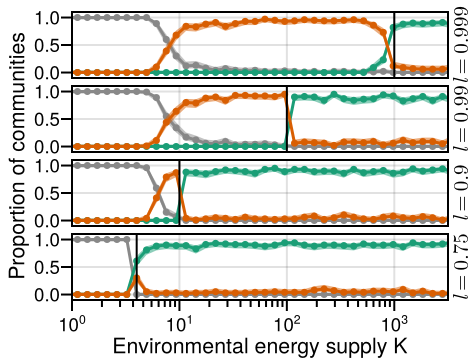

In [5]:
faflis = []
fafcounts = Any[]

for i in 2:5
    push!(faflis, small_lis[i])
    push!(fafcounts, small_rslts[:,i])
end
@show faflis
faflabels = [
    L"l=0.999",
    L"l=0.99",
    L"l=0.9",
    L"l=0.75",
]

fig = Figure(;
    size=(double_col_width * 0.35, 0.43 * double_col_width / golden_ratio),
    figure_padding=(2., 2., 2., 6.),
)

axs = []
for i in 1:length(faflis)
    li = faflis[i]
    cs = fafcounts[i]

    ax = Axis(fig[i,1];
        xscale=log10,
        xticklabelsize=7fontsize_pt,
        yticklabelsize=7fontsize_pt,
        xticklabelpad=0.,
        yticklabelpad=0.,
        xticks=log10ticks(0:5),
        xminorticksvisible=true,
        xminorticks=IntervalsBetween(10),
    )
    push!(axs, ax)
    Label(fig[i,2], faflabels[i];
        rotation=pi/2,
        tellheight=false,
        fontsize=7fontsize_ltex_pt,
    )
    
    num_runs = [x.num_runs for x in cs]
    plot_binom_sample!(ax, small_Ks, [x.extinct for x in cs], num_runs;
        color=PaperColors.extinct(),
        sl_kwargs=(; markersize=5.),
        proportions=true,
    )
    plot_binom_sample!(ax, small_Ks, [x.nonext_stable for x in cs], num_runs;
        color=PaperColors.stable(),
        sl_kwargs=(; markersize=5.),
        proportions=true,
    )
    plot_binom_sample!(ax, small_Ks, [x.nonext_unstable for x in cs], num_runs;
        color=PaperColors.unstable(),
        sl_kwargs=(; markersize=5.),
        proportions=true,
    )
        
    thrbdr = 1 / (1 - li)
    if isfinite(thrbdr)
        vlines!(ax, thrbdr;
            color=:black,
            linewidth=1.,
        )
    end

    xlims!(ax, 1, 10 ^ 3.5)
    ylims!(ax, -0.1, 1.1)
end

for i in 1:(length(axs)-1)
    linkxaxes!(axs[end], axs[i])
    hidexdecorations!(axs[i]; grid=false)
end

Label(fig[1:4,0], "Proportion of communities";
    rotation=pi/2,
    tellheight=false,
    fontsize=8fontsize_pt,
)
Label(fig[5,1], "Environmental energy supply K";
    tellwidth=false,
    fontsize=8fontsize_pt,
)
@show size(fig.layout)

rowgap!(fig.layout, 4.)
rowgap!(fig.layout, 4, 0.)
colgap!(fig.layout, 1, 4.)
colgap!(fig.layout, 2, 2.)

Makie.save("../../figures2/fig1/outcomes.pdf", fig)

fig

# Well-mixed total biomass vs K plot

In [11]:
li_ii = 2
@show small_lis[li_ii]



small_lis[li_ii] = 0.999

0.999

In [6]:
tbli = f1md.lis[end]
tbdf = @subset(f1df, :liis .== maximum(f1df.liis), :codes .> 0);
tbdf.K = f1md.Ks[tbdf.Kis]
tbdf.hss_biomass = map(tbdf.final_states) do fs sum(fs[1:f1md.N]) end;
tbdf.hss_biomass_clamped = clamp.(tbdf.hss_biomass, 0., Inf);

# smallest nonzero biomass is ~0.21, so the linear core sits just below the data and
# the extinct points at 0 stay ~0.5 decades clear of the smallest surviving ones
linthresh = 0.1

fig = Figure(;
    size=(double_col_width * 0.29, 0.3 * double_col_width / golden_ratio),
    figure_padding=(2., 2., 2., 6.),
)

ax = Axis(fig[1,1];
    xlabel="Environmental energy supply K",
    ylabel="Total biomass",
    xlabelsize=8fontsize_pt,
    ylabelsize=8fontsize_pt,
    ylabelpadding=0.,
    xlabelpadding=0.,
    xscale=log10,
    # symlog so the exactly-zero (extinct) biomasses are on the axis
    CustomSymlogScale.kwargs(linthresh; nminor=4)...,
    yticks=CustomSymlogScale.ticks([0.; 10.0 .^ (0:4)]),
    xticklabelsize=7fontsize_pt,
    yticklabelsize=7fontsize_pt,
    xticklabelpad=0.,
    yticklabelpad=0.,
    xticks=log10ticks(0:4),
    xminorticksvisible=true,
    xminorticks=IntervalsBetween(10),
)

scatter!(ax, tbdf.K, tbdf.hss_biomass_clamped;
    # color=(color, 0.3),
    color=(:black, 0.3),
    markersize=3.,
    strokewidth=0.,
)

# xlims!(ax, 10^-0.6, 10^4.2)
ylims!(ax, -linthresh, 2e4)

text!(ax, 0.01, 0.99;
    text=latexstring(@sprintf "l=%.3f" tbli),
    space=:relative,
    align=(:left, :top),
    fontsize=7fontsize_ltex_pt,
)

Makie.save("../../figures2/fig1/hss_biomass.pdf", fig)

fig

LoadError: UndefVarError: `f1md` not defined